# Task 4 — Customer Data Analysis

## UCI Online Retail II Dataset

**Internship:** CODSOFT Data Analytics Internship  
**Tools:** Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook

### Objective
- Analyze customer purchasing behavior
- Segment customers based on location and buying patterns
- Identify valuable customer groups
- Create visual reports to summarize customer insights
- Suggest marketing strategies based on the analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path = r"C:\Users\ITGADGET\Desktop\CODSOFT_DATA_ANALYTICS\Task 1\Data\cleaned_online_retail.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1050081, 8)


In [3]:
print("Columns in the dataset:")
print(df.columns.tolist())

print("\nCustomer ID information:")
print(df["Customer ID"].dtype)
print("Missing Customer IDs:", df["Customer ID"].isna().sum())
print("Unique Customers:", df["Customer ID"].nunique())

Columns in the dataset:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Customer ID information:
float64
Missing Customer IDs: 237713
Unique Customers: 5942


In [4]:
df["TotalAmount"] = df["Quantity"] * df["Price"]

customer_sales = (
    df.groupby("Customer ID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 customers by total purchase value:")
display(customer_sales.head(10))

Top 10 customers by total purchase value:


Customer ID
18102.0    598215.22
14646.0    523342.07
14156.0    296378.14
14911.0    270169.49
17450.0    233419.39
13694.0    190862.96
17511.0    171885.98
12415.0    143269.29
16684.0    141502.25
15061.0    136391.48
Name: TotalAmount, dtype: float64

In [5]:
customer_orders = (
    df.groupby("Customer ID")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 customers by number of orders:")
display(customer_orders.head(10))

Top 10 customers by number of orders:


Customer ID
14911.0    510
12748.0    365
17841.0    289
15311.0    270
14606.0    259
13089.0    247
14156.0    202
14527.0    190
13694.0    164
14646.0    164
Name: Invoice, dtype: int64

In [6]:
country_customer_sales = (
    df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by customer purchase value:")
display(country_customer_sales)

Top 10 countries by customer purchase value:


Country
United Kingdom    1.647644e+07
EIRE              6.152291e+05
Netherlands       5.485233e+05
Germany           4.174299e+05
France            3.279967e+05
Australia         1.670616e+05
Switzerland       9.970646e+04
Spain             9.180816e+04
Sweden            8.777552e+04
Denmark           6.574109e+04
Name: TotalAmount, dtype: float64

In [7]:
customer_summary = pd.DataFrame({
    "TotalSpend": customer_sales,
    "OrderFrequency": customer_orders
}).dropna()

q25 = customer_summary["TotalSpend"].quantile(0.25)
q75 = customer_summary["TotalSpend"].quantile(0.75)

customer_summary["CustomerSegment"] = customer_summary["TotalSpend"].apply(
    lambda x: "High Value" if x >= q75
    else "Low Value" if x <= q25
    else "Regular"
)

print("Customer segments:")
display(customer_summary.head(10))

print("\nSegment distribution:")
display(customer_summary["CustomerSegment"].value_counts())

Customer segments:


,TotalSpend,OrderFrequency,CustomerSegment
Customer ID,,,
12346.0,-51.74,17,Low Value
12347.0,5633.32,8,High Value
12348.0,2019.40,5,Regular
12349.0,4404.54,5,High Value
12350.0,334.40,1,Regular
12351.0,300.93,1,Low Value
12352.0,1889.21,13,Regular
12353.0,406.76,2,Regular
12354.0,1079.40,1,Regular



Segment distribution:


CustomerSegment
Regular       2970
Low Value     1486
High Value    1486
Name: count, dtype: int64

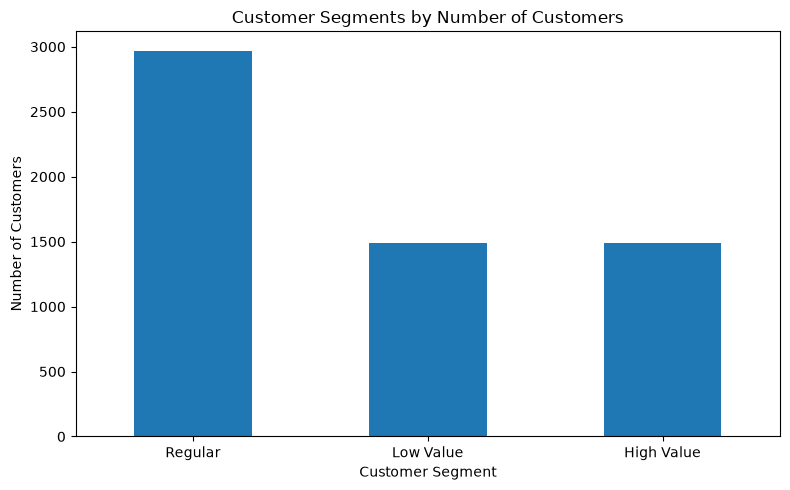

In [8]:
segment_counts = customer_summary["CustomerSegment"].value_counts()

plt.figure(figsize=(8, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Segments by Number of Customers")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [9]:
segment_spending = (
    customer_summary.groupby("CustomerSegment")["TotalSpend"]
    .sum()
    .sort_values(ascending=False)
)

print("Total spending by customer segment:")
display(segment_spending)

Total spending by customer segment:


CustomerSegment
High Value    1.359769e+07
Regular       2.837253e+06
Low Value     1.584512e+05
Name: TotalSpend, dtype: float64

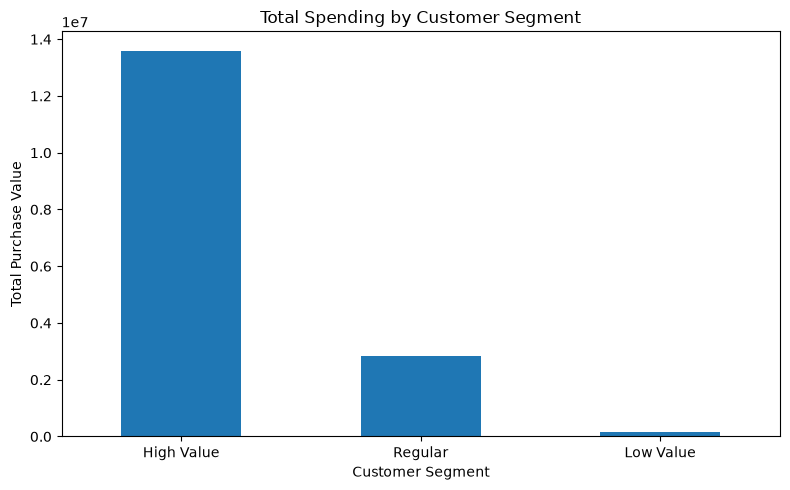

In [10]:
plt.figure(figsize=(8, 5))

segment_spending.plot(kind="bar")

plt.title("Total Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Purchase Value")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

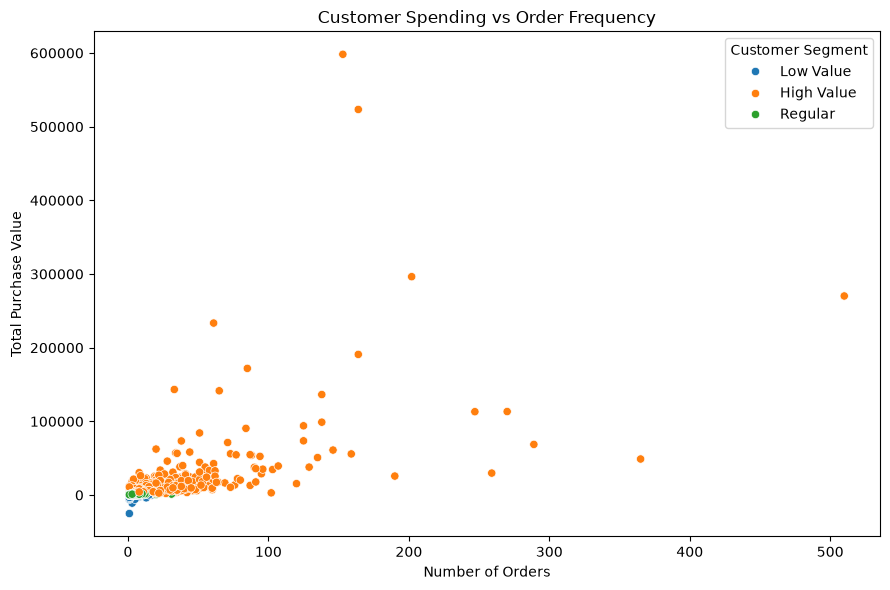

In [11]:
id="p7k3lm"
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_summary,
    x="OrderFrequency",
    y="TotalSpend",
    hue="CustomerSegment"
)

plt.title("Customer Spending vs Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Total Purchase Value")
plt.legend(title="Customer Segment")

plt.tight_layout()
plt.show()

In [12]:
customer_country = (
    df.dropna(subset=["Customer ID"])
      .groupby("Country")["Customer ID"]
      .nunique()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 countries by number of customers:")
display(customer_country)

Top 10 countries by number of customers:


Country
United Kingdom    5410
Germany            107
France              95
Spain               41
Belgium             29
Portugal            24
Netherlands         23
Switzerland         22
Sweden              19
Italy               17
Name: Customer ID, dtype: int64

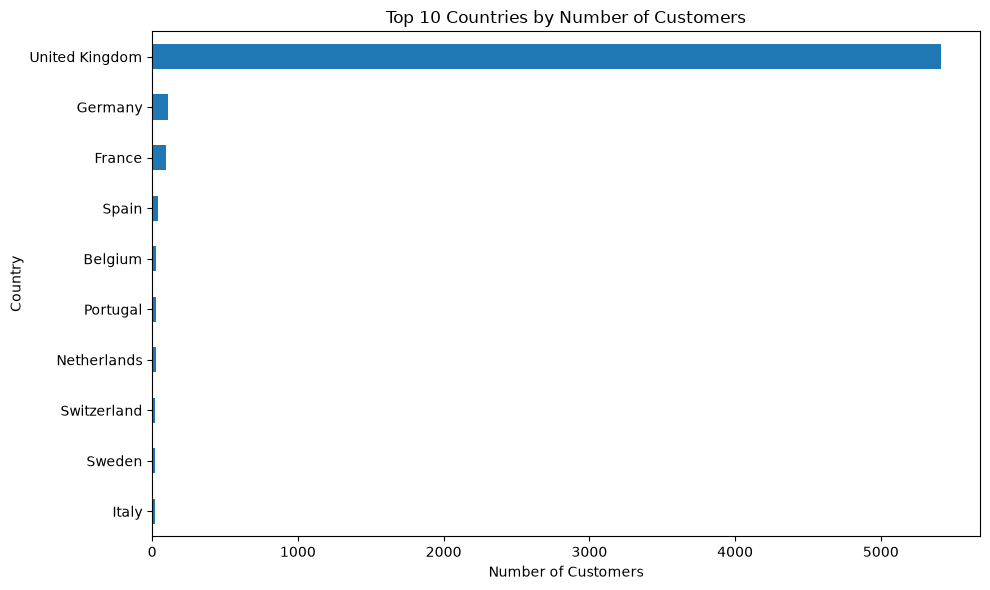

In [13]:
plt.figure(figsize=(10, 6))

customer_country.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Number of Customers")
plt.xlabel("Number of Customers")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [14]:
customer_summary_sorted = customer_summary.sort_values(
    by="TotalSpend",
    ascending=False
)

print("Top 10 valuable customers:")
display(customer_summary_sorted.head(10))

Top 10 valuable customers:


,TotalSpend,OrderFrequency,CustomerSegment
Customer ID,,,
18102.0,598215.22,153,High Value
14646.0,523342.07,164,High Value
14156.0,296378.14,202,High Value
14911.0,270169.49,510,High Value
17450.0,233419.39,61,High Value
13694.0,190862.96,164,High Value
17511.0,171885.98,85,High Value
12415.0,143269.29,33,High Value
16684.0,141502.25,65,High Value


In [15]:
customer_avg_order = (
    df.dropna(subset=["Customer ID"])
      .groupby("Customer ID")["TotalAmount"]
      .mean()
      .sort_values(ascending=False)
)

print("Top 10 customers by average order value:")
display(customer_avg_order.head(10))

Top 10 customers by average order value:


Customer ID
15195.0    3861.000000
13205.0    2803.200000
17846.0    2033.100000
12737.0    1855.250000
16532.0    1459.440000
15749.0    1435.726667
16000.0    1377.077778
17369.0     979.200000
17876.0     856.005000
14091.0     733.083077
Name: TotalAmount, dtype: float64

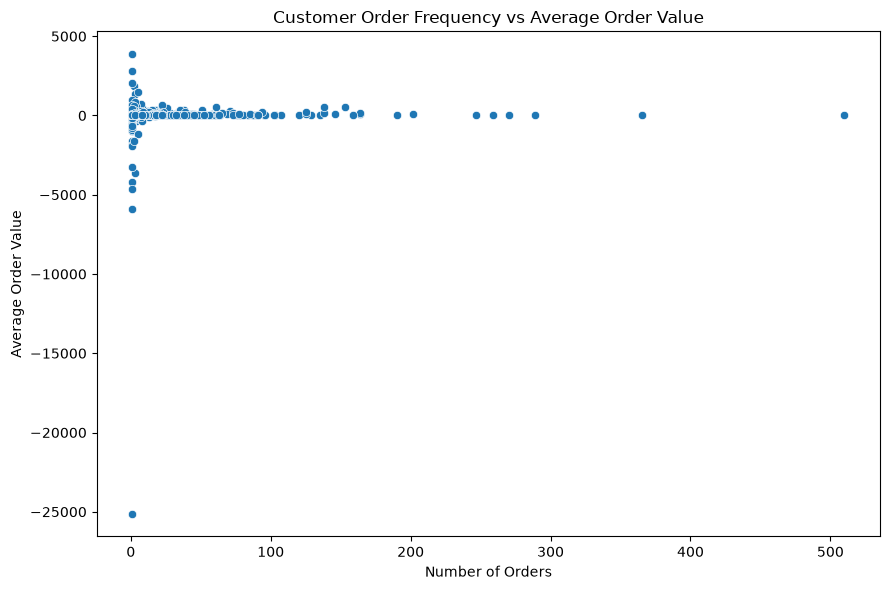

In [16]:
customer_behavior = pd.DataFrame({
    "OrderFrequency": customer_orders,
    "AverageOrderValue": customer_avg_order
}).dropna()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_behavior,
    x="OrderFrequency",
    y="AverageOrderValue"
)

plt.title("Customer Order Frequency vs Average Order Value")
plt.xlabel("Number of Orders")
plt.ylabel("Average Order Value")

plt.tight_layout()
plt.show()

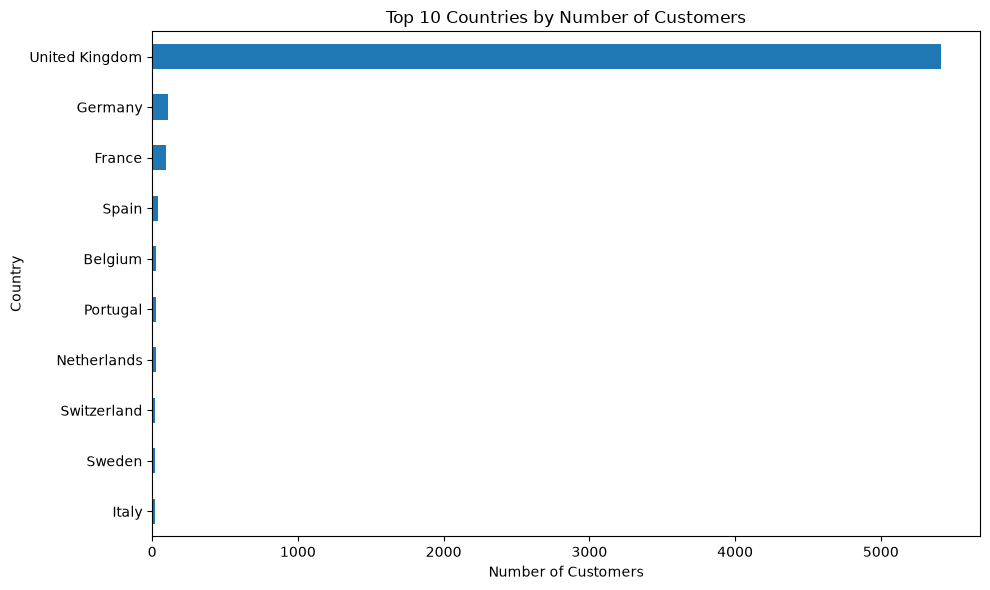

In [17]:
plt.figure(figsize=(10, 6))

customer_country.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Number of Customers")
plt.xlabel("Number of Customers")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

> **Dataset Limitation:** The UCI Online Retail II dataset does not contain an age field. Therefore, customer segmentation in this analysis focuses on **location and purchasing behavior**, including spending, order frequency, and average order value.

## Suggested Marketing Strategies

Based on the customer purchasing behavior and segmentation analysis, the following strategies can be considered:

### 1. High Value Customers
- Provide loyalty rewards and exclusive offers.
- Encourage repeat purchases through personalized promotions.
- Introduce early access to selected products or campaigns.

### 2. Regular Customers
- Use targeted discounts to encourage more frequent purchases.
- Recommend products based on previous purchasing behavior.
- Create bundle offers to increase order value.

### 3. Low Value Customers
- Use introductory offers and targeted promotions to encourage purchases.
- Identify products commonly purchased by these customers and create relevant recommendations.
- Use reminder campaigns to encourage repeat purchases.

### 4. Location-Based Marketing
- Focus marketing campaigns on regions with a larger customer base.
- Analyze country-level purchasing patterns to develop region-specific promotions.
- Allocate marketing efforts based on customer activity and purchase value.

In [18]:
print("===== TASK 4 FINAL VALIDATION =====")

print("Dataset shape:", df.shape)
print("Unique customers:", df["Customer ID"].nunique())
print("Customer segments:", customer_summary["CustomerSegment"].nunique())
print("Countries analyzed:", df["Country"].nunique())

print("\nCustomer Segment Counts:")
display(customer_summary["CustomerSegment"].value_counts())

print("\nMissing values in customer summary:")
display(customer_summary.isnull().sum())

print("\nTask 4 validation completed successfully!")

===== TASK 4 FINAL VALIDATION =====
Dataset shape: (1050081, 9)
Unique customers: 5942
Customer segments: 3
Countries analyzed: 43

Customer Segment Counts:


CustomerSegment
Regular       2970
Low Value     1486
High Value    1486
Name: count, dtype: int64


Missing values in customer summary:


TotalSpend         0
OrderFrequency     0
CustomerSegment    0
dtype: int64


Task 4 validation completed successfully!


## Conclusion

This analysis provided insights into customer purchasing behavior using spending, order frequency, average order value, and location-based analysis.

Customer segmentation helped identify different groups based on their purchasing value, while visualizations made it easier to understand customer patterns and differences between segments.

The analysis demonstrates how customer data can be transformed into actionable business insights that can support customer retention, targeted marketing, and data-driven decision-making.

> **Note:** Customer age was not analyzed because the dataset does not contain an age field. The analysis therefore focuses on location and purchasing behavior.